# Categorical 51-atom distributional reinforcement learning (C51) in JAX+Flax.NNX

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
# Example implementations:
# https://github.com/vwxyzjn/cleanrl/blob/master/cleanrl/c51_jax.py
# https://towardsdatascience.com/rainbow-the-colorful-evolution-of-deep-q-networks-37e662ab99b2/
# https://github.com/tinker495/jax-baseline/blob/main/jax_baselines/C51/c51.py

In [3]:
import jax
from jax.typing import ArrayLike
from jax import numpy as jnp # JAX version of NumPy.
from flax import nnx # Neural networks in JAX.
import optax # Optimization in JAX.
import gymnasium as gym
import numpy as np # For compatibility with gymnasium.
from tqdm import tqdm

In [4]:
from qnrl.buffers import ReplayBuffer

In [5]:
class DistQNet(nnx.Module):
    """Distributional Q-value network.
    
    Creates a probability mass function (PMF) across the space of return-atoms for every action.
    
    Citation: https://doi.org/10.48550/arXiv.1707.06887
    """
    def __init__(self, din: int, num_actions: int, num_atoms: int, z_min: float, z_max: float, *, rngs: nnx.Rngs, douts: list[int] = []):
        
        # Organize dimensions so that the output of one is the input of another.
        dims = [din, *douts, num_actions * num_atoms]
        din_dout = list(zip(dims[:-1], dims[1:])) # (din, dout)
        self.layers = [
            nnx.Linear(in_features=in_features, out_features=out_features, rngs=rngs)
            for in_features, out_features in din_dout
        ]
        self.din = din
        self.num_actions = num_actions
        self.num_atoms = num_atoms
        self.douts = douts
        self.z_min = z_min
        self.z_max = z_max
        
        self.atoms = nnx.Variable(jnp.linspace(start=z_min, stop=z_max, num=num_atoms))
    
    @nnx.jit
    def __call__(self, x):
        # Apply layer+ReLU to all except last layer.
        for layer in self.layers[:-1]:
            x = layer(x)
            x = nnx.relu(x)
        # Generate return-atom distribution using last layer.
        x = self.layers[-1](x)
        x = x.reshape((x.shape[0], self.num_actions, self.num_atoms)) # (batch, action, atom)
        x = nnx.softmax(x, axis=-1) # Distribution over the atoms for every action.
        return x

In [6]:
# Seed the random number generators.
seed = 0
np.random.seed(seed)
key = jax.random.PRNGKey(seed)
key, subkey = jax.random.split(key)

In [7]:
batch_size = 128
total_timesteps = 500_000
learning_starts = 10_000
train_frequency = 10
target_network_frequency = 500
gamma = 0.99
tau = 1.0
report_frequency = 100
buffer_size = 10_000
eps_start = 1
eps_end = 5e-2
eps_exploration = 0.5

In [8]:
# Initialize the environment.
env_name = 'CartPole-v1'
num_envs = 1
envs = gym.make_vec(env_name, num_envs=num_envs, vectorization_mode="sync", wrappers=[gym.wrappers.RecordEpisodeStatistics])
envs.action_space.seed(seed)

num_actions = int(envs.single_action_space.n)
obs_shape = envs.observation_space.shape

In [9]:
din = int(jnp.prod(jnp.array(obs_shape[1:])))
num_atoms = 101
key, subkey = jax.random.split(key)
model_policy = DistQNet(
    din=din,
    num_actions=num_actions,
    num_atoms=num_atoms,
    z_min=-100,
    z_max=100,
    douts=[120, 84],
    rngs=nnx.Rngs(key),
)
model_target = DistQNet(
    din=din,
    num_actions=num_actions,
    num_atoms=num_atoms,
    z_min=-100,
    z_max=100,
    douts=[120, 84],
    rngs=nnx.Rngs(key),
)
optimizer = nnx.Optimizer(model_policy, optax.adam(learning_rate=2.5e-4, eps=0.01/batch_size), wrt=nnx.Param)
nnx.display(model_policy)

In [10]:
observations, _ = envs.reset(seed=seed) # Reset the environment.
observations = jnp.asarray(observations) # (num_envs, *obs_shape), environment axis is treated as batch index.
print(observations)
pmf = model_policy(observations)
nnx.display(pmf)

[[ 0.01369617 -0.02302133 -0.04590265 -0.04834723]]


In [11]:
# https://github.com/google-deepmind/rlax/blob/master/rlax/_src/value_learning.py#L543#L602
# @nnx.jit
# def categorical_project(
    
# ):
#     pass


@nnx.jit
def update(
    optimizer: nnx.Optimizer,
    model_policy: DistQNet,
    model_target: DistQNet,
    observations: jax.Array,
    actions: jax.Array,
    next_observations: jax.Array,
    rewards: jax.Array,
    dones: jax.Array,
    gamma: float,
    ):
    batch_idx = jnp.arange(actions.shape[0])
    # Generate batch of return-atom distributions for every action.
    next_pmfs = model_target(next_observations) # (batch_size, num_actions, n_atoms)
    # Compute estimated Q-value, which is the expected value of the return-atom distribution.
    next_vals = (next_pmfs * model_policy.atoms).sum(axis=-1) # (batch_size, num_actions)
    # Determine the optimum action according to max (greedy) Q-value estimate.
    next_action = jnp.argmax(next_vals, axis=-1) # (batch_size,)
    # Get the return-atom distribution corresponding to the optimum action.
    next_pmfs = next_pmfs[batch_idx, next_action] # (batch_size, n_atoms)
    # next_pmfs = next_pmfs[:, next_action] # (batch_size, n_atoms)
    # Compute the atoms of the target distribution and clip to range [z_min, z_max], which are not aligned with the original distribution.
    tz = rewards[:, jnp.newaxis] + gamma * model_policy.atoms * (1 - dones)[:, jnp.newaxis] # (batch_size, num_atoms)
    tz = jnp.clip(tz, a_min=model_policy.z_min, a_max=model_policy.z_max) # Clip to range [z_min, z_max].
    # Project the current atoms to the target atoms.
    dz = model_policy.atoms[1] - model_policy.atoms[0] # Delta z.
    b = (tz - model_policy.z_min) / dz
    l = jnp.clip(jnp.floor(b), a_min=0, a_max=model_policy.num_atoms - 1) # (batch_size, num_atoms), Lower (left) bin index.
    u = jnp.clip(jnp.ceil(b), a_min=0, a_max=model_policy.num_atoms - 1) # (batch_size, num_atoms), Upper (right) bin index.
    dml = (u - b) * next_pmfs # (batch_size, num_atoms), Split the weight onto the lower bin.
    dmu = (b - l) * next_pmfs # (batch_size, num_atoms), Split the weight onto the upper bin.
    
    # TODO replace this with `jax.vmap` and `categorical_project`.
    # def project_to_bins(i: int, val: jax.Array):
    #     """Apply a [lower,upper] offset to the value of the current bin index."""
    #     print(f"{i = }, {val = }")
    #     val = val.at[i, l[i].astype(jnp.int32)].add(dml[i])
    #     val = val.at[i, u[i].astype(jnp.int32)].add(dmu[i])
    # target_pmfs = jnp.zeros_like(next_pmfs)
    # target_pmfs = jax.lax.fori_loop(0, target_pmfs.shape[0], project_to_bins, target_pmfs)
    # 
    # 
    def project_to_bins(target_pmfs: jax.Array, l: jax.Array, u: jax.Array, dml: jax.Array, dmu: jax.Array):
        """Project an instance of return atoms. Apply to batches using `jax.vmap`."""
        target_pmfs = target_pmfs.at[l.astype(jnp.int32)].add(dml)
        target_pmfs = target_pmfs.at[u.astype(jnp.int32)].add(dmu)
        return target_pmfs
    
    target_pmfs = jax.vmap(project_to_bins)(jnp.zeros_like(next_pmfs), l, u, dml, dmu)
    
    # nnx.display(dict(rewards=rewards, atoms=model_policy.atoms, dones=dones, tz=tz, dml=dml, dmu=dmu, l=l, u=u, b=b, target_pmfs=target_pmfs))
    
    # Categorical cross-entropy loss.
    def cross_entropy_loss(model, x, actions, y):
        batch_idx = jnp.arange(x.shape[0])
        y_hat = model(x)
        # Get the return-atom distribution corresponding to the given actions.
        # old_pmfs = pmfs[batch_idx, actions.squeeze()] # (batch_size, n_atoms)
        y_hat = y_hat[batch_idx, actions.squeeze()] # (batch_size, n_atoms)
        y_hat = jnp.clip(y_hat, a_min=1e-5, a_max=1 - 1e-5) # Clip the PMFs for passing to the log, to prevent -inf and 0.
        loss = -jnp.sum(y * jnp.log(y_hat), axis=-1) # (batch_size,)
        return loss.mean()
    
    loss, grads = nnx.value_and_grad(cross_entropy_loss)(model=model_policy, x=observations, actions=actions, y=target_pmfs)
    optimizer.update(model_policy, grads) # Update the policy Q-network in-place.
    
    return loss

In [12]:
def epsilon_schedule_linear(eps_start: float, eps_end: float, duration: int, t: int):
    """Linear epsilon decay schedule."""
    slope = (eps_end - eps_start) / duration
    return max(slope * t, eps_end)

In [13]:
###
# Run the environment.
###
buffer = ReplayBuffer(buffer_size=buffer_size, env=envs)
observations, _ = envs.reset(seed=seed) # Reset the environment.
observations = jnp.asarray(observations) # (num_envs, *obs_shape), environment axis is treated as batch index.
print(f"{observations.shape = }")
pbar = tqdm(range(total_timesteps), unit='step', desc="waiting to train", leave=True)
postfix = dict()
history = []
for t in pbar:
    
    # Action selection.
    eps = epsilon_schedule_linear(eps_start=eps_start, eps_end=eps_end, duration=int(eps_exploration*total_timesteps), t=t)
    key, subkey = jax.random.split(key)
    if jax.random.uniform(key=subkey) < eps: # Explore via random action selection.
        actions = jnp.asarray(envs.action_space.sample())
    else:
        # q_values = model_policy(observations) # (num_envs, num_actions), environment axis is treated as batch index.
        # actions = q_values.argmax(axis=-1) # (num_envs,)
        # 
        pmfs = model_policy(observations)
        q_vals = jnp.sum(pmfs * model_policy.atoms, axis=-1)
        actions = jnp.argmax(q_vals, axis=-1)
    
    # Interaction within environment using selected actions.
    # print(f"{actions.tolist() = }")
    next_observations, rewards, dones, truncations, infos = envs.step(np.array(actions))
    buffer.add(observations, next_observations, actions, rewards, dones) # Push interaction onto buffer.
    
    if "episode" in infos:
        postfix.update(dict(episode_return=infos['episode']['r'], episode_length=infos['episode']['l']))
        history.append(dict(t_episode=t, episode_return=infos['episode']['r'], episode_length=infos['episode']['l']))
    
    if t % report_frequency == 0:
        pbar.set_postfix(postfix)
    
    # Override current observation to be the next observation for subsequent loop iteration.
    observations = next_observations.copy()
    
    if t > learning_starts:
        if t % train_frequency == 0:
            # Update the policy model via a gradient descent step on a minibatch of samples.
            key, subkey = jax.random.split(key)
            minibatch = buffer.sample(key=subkey, batch_size=batch_size)
            loss = update(
                optimizer=optimizer,
                model_policy=model_policy,
                model_target=model_target,
                observations=minibatch.observations,
                actions=minibatch.actions,
                next_observations=minibatch.next_observations,
                rewards=minibatch.rewards,
                dones=minibatch.dones,
                gamma=gamma,
                )
            
            if t % report_frequency == 0:
                pbar.set_description("training", refresh=False)
                postfix.update(dict(loss=loss, t=t))
                pbar.set_postfix(postfix)
                
                history.append(dict(loss=loss, t_loss=t))
        
        if t % target_network_frequency == 0:
            params_policy = nnx.state(model_policy, nnx.Param) # Get the learnable parameters of the policy model.
            params_target = nnx.state(model_target, nnx.Param) # Get the learnable parameters of the target model.
            params_update = optax.incremental_update(params_policy, params_target, tau) # Apply soft update rule for target network weights.
            nnx.update(model_target, params_update)

/Users/derieux/research/qnrl/qnrl/buffers.py:75: UserWarning: Explicitly requested dtype int64 requested in zeros is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  self.actions = jnp.zeros(shape=(self.buffer_size, *self.action_shape), dtype=self.action_space.dtype)


observations.shape = (1, 4)


training: 100%|██████████| 500000/500000 [12:26<00:00, 670.05step/s, episode_return=[500.], episode_length=[500], loss=0.49286222, t=5e+5]  


In [14]:
# nnx.display(history)

In [15]:
def listofdict_to_dictoflist(listofdict: list[dict]) -> dict[str,jax.Array]:
    res = {}
    for d in listofdict:
        for k,v in d.items():
            res.setdefault(k, []).append(v)
    res = {k: jnp.array(v) for k,v in res.items()}
    return res

In [16]:
hdict = listofdict_to_dictoflist(history)
hdict

{'t_episode': Array([     7,     18,     29, ..., 498529, 499030, 499531], dtype=int32),
 'episode_return': Array([[  8.],
        [ 10.],
        [ 10.],
        ...,
        [500.],
        [500.],
        [500.]], dtype=float32),
 'episode_length': Array([[  8],
        [ 10],
        [ 10],
        ...,
        [500],
        [500],
        [500]], dtype=int32),
 'loss': Array([4.4891224 , 4.4854302 , 4.488941  , ..., 0.5102955 , 0.48878   ,
        0.49286222], dtype=float32),
 't_loss': Array([ 10100,  10200,  10300, ..., 499700, 499800, 499900], dtype=int32)}

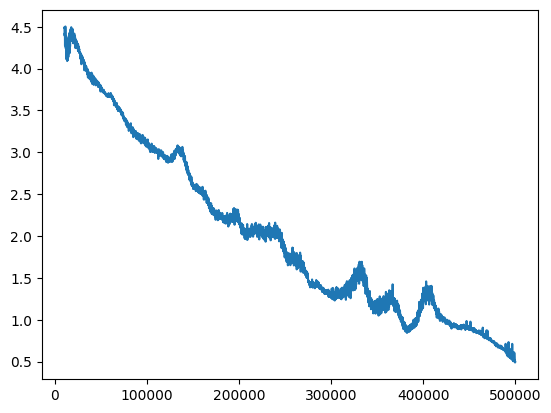

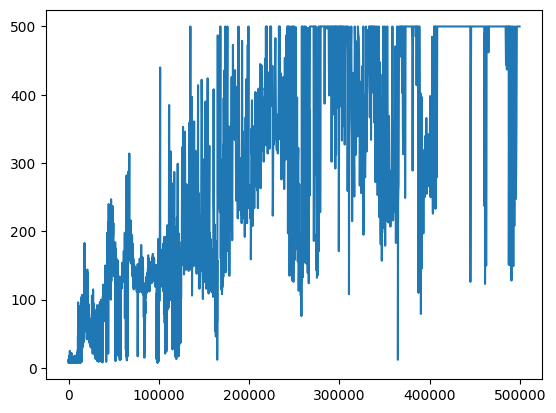

In [19]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(hdict['t_loss'], hdict['loss'])

plt.figure()
plt.plot(hdict['t_episode'], hdict['episode_return'].mean(axis=-1))

In [20]:
###
# Evaluate the model.
###
observations, _ = envs.reset() # Reset the environment.
for t in range(total_timesteps):
    pmfs = model_policy(observations)
    q_vals = jnp.sum(pmfs * model_policy.atoms, axis=-1)
    actions = jnp.argmax(q_vals, axis=-1)
    next_observations, rewards, dones, truncations, infos = envs.step(np.array(actions))
    if any(dones):
        break
    
    # Update current observation with next observation.
    observations = next_observations.copy()
    
nnx.display(infos)